In [22]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
import os
DATA_DIR = "/content/drive/MyDrive/clv-preprocessing/data"
print(os.listdir(DATA_DIR))

['Online Retail.xlsx']


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_excel(f"{DATA_DIR}/Online Retail.xlsx", dtype={"CustomerID": "string"})
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])
df["CustomerID"] = df["CustomerID"].str.replace(r"\.0$", "", regex=True)
df.to_csv(f"{DATA_DIR}/online_retail.csv", index=False)   # faster copy for next time
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom


In [5]:
df = pd.read_csv(f"{DATA_DIR}/online_retail.csv", dtype={"CustomerID": "string"}, parse_dates=["InvoiceDate"])

In [6]:
print(df.shape)
print(df.dtypes)
print(df["InvoiceDate"].min(), "to", df["InvoiceDate"].max())
print(df["CustomerID"].nunique(), "unique customers")

(541909, 8)
InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
UnitPrice             float64
CustomerID     string[python]
Country                object
dtype: object
2010-12-01 08:26:00 to 2011-12-09 12:50:00
4372 unique customers


In [7]:
quality = {
    "total_rows": len(df),
    "missing_customer_id": int(df["CustomerID"].isna().sum()),
    "duplicate_rows": int(df.duplicated().sum()),
    "cancelled_invoices": int(df["InvoiceNo"].astype(str).str.startswith("C").sum()),
    "bad_quantity_or_price": int(((df["Quantity"] <= 0) | (df["UnitPrice"] <= 0)).sum()),
}
quality

{'total_rows': 541909,
 'missing_customer_id': 135080,
 'duplicate_rows': 5268,
 'cancelled_invoices': 9288,
 'bad_quantity_or_price': 11805}

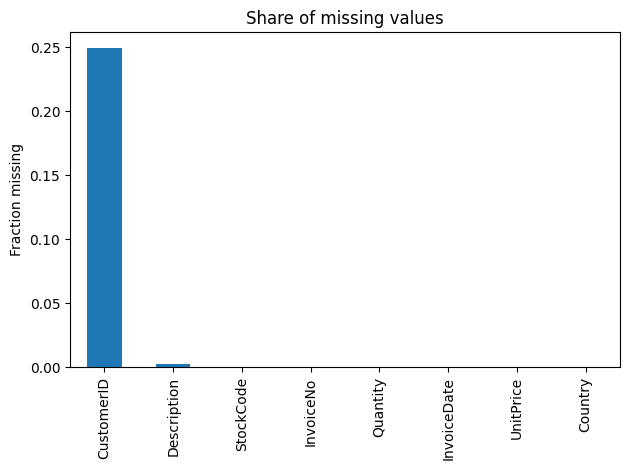

In [8]:
df.isna().mean().sort_values(ascending=False).plot(kind="bar", title="Share of missing values")
plt.ylabel("Fraction missing")
plt.tight_layout()
plt.show()

In [9]:
def clean(df):
    log = {"start_rows": len(df)}

    n = len(df); df = df.dropna(subset=["CustomerID"])
    log["removed_missing_id"] = n - len(df)

    n = len(df); df = df.drop_duplicates()
    log["removed_duplicates"] = n - len(df)

    n = len(df); df = df[~df["InvoiceNo"].astype(str).str.startswith("C")]
    log["removed_cancelled"] = n - len(df)

    n = len(df); df = df[(df["Quantity"] > 0) & (df["UnitPrice"] > 0)]
    log["removed_invalid_values"] = n - len(df)

    df = df.assign(Revenue=df["Quantity"] * df["UnitPrice"])
    log["final_rows"] = len(df)
    log["final_customers"] = df["CustomerID"].nunique()
    return df, log

In [10]:
clean_df, log = clean(df)
pd.Series(log).to_csv(f"{DATA_DIR}/cleaning_log.csv")
pd.Series(log)

,0
start_rows,541909
removed_missing_id,135080
removed_duplicates,5225
removed_cancelled,8872
removed_invalid_values,40
final_rows,392692
final_customers,4338


In [11]:
cutoff = pd.Timestamp("2011-09-09")
past   = clean_df[clean_df["InvoiceDate"] <  cutoff]
future = clean_df[clean_df["InvoiceDate"] >= cutoff]
print(len(past), len(future))

232576 160116


In [12]:
feat = past.groupby("CustomerID").agg(
    last_order=("InvoiceDate", "max"),
    first_order=("InvoiceDate", "min"),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("Revenue", "sum"),
)
feat["Recency"]       = (cutoff - feat["last_order"]).dt.days
feat["CustomerAge"]   = (cutoff - feat["first_order"]).dt.days
feat["AvgOrderValue"] = feat["Monetary"] / feat["Frequency"]
feat = feat.drop(columns=["last_order", "first_order"])
feat.head()

,Frequency,Monetary,Recency,CustomerAge,AvgOrderValue
CustomerID,,,,,
12346,1,77183.60,233,233,77183.600000
12347,5,2790.86,37,275,558.172000
12348,3,1487.24,156,266,495.746667
12350,1,334.40,218,218,334.400000
12352,5,1561.81,170,204,312.362000


In [13]:
target = future.groupby("CustomerID")["Revenue"].sum().rename("CLV")
data = feat.join(target).fillna({"CLV": 0})
data.describe()

,Frequency,Monetary,Recency,CustomerAge,AvgOrderValue,CLV
count,3362.000000,3362.000000,3362.000000,3362.000000,3362.000000,3362.000000
mean,3.524093,1611.509751,93.830161,181.336109,397.488837,851.554944
std,5.772452,6151.180679,79.644330,80.059700,1424.166167,5014.920605
min,1.000000,2.900000,0.000000,0.000000,2.900000,0.000000
25%,1.000000,263.905000,25.000000,121.000000,168.355000,0.000000
50%,2.000000,562.600000,73.000000,192.000000,283.077000,175.355000
75%,4.000000,1384.052500,150.000000,263.000000,413.212000,700.280000
max,131.000000,178302.620000,281.000000,281.000000,77183.600000,168469.600000


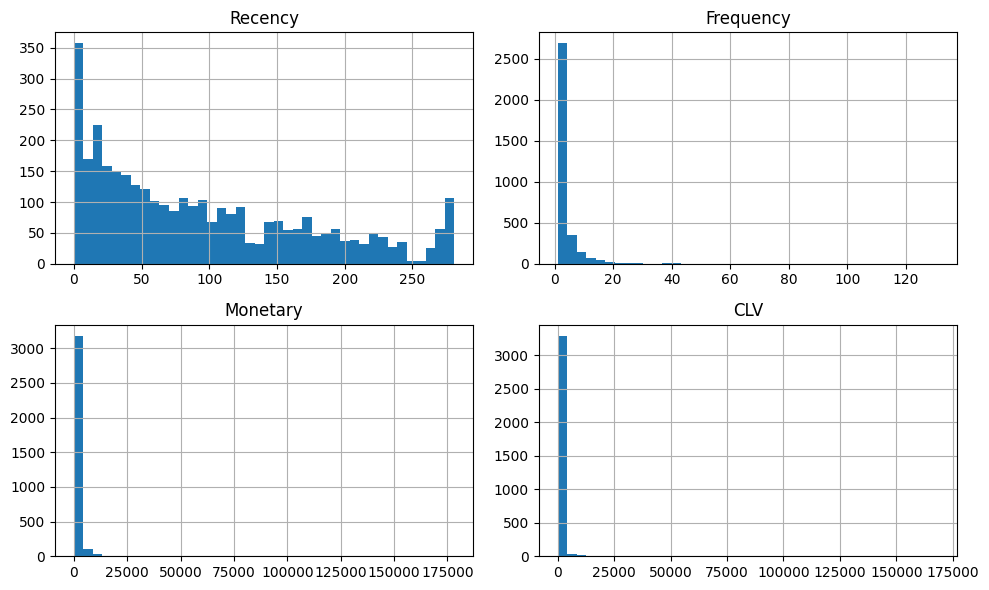

In [14]:
data[["Recency", "Frequency", "Monetary", "CLV"]].hist(bins=40, figsize=(10, 6))
plt.tight_layout()
plt.show()

In [15]:
from sklearn.model_selection import train_test_split

cols = ["Recency", "Frequency", "Monetary", "AvgOrderValue", "CustomerAge"]
train, test = train_test_split(data, test_size=0.2, random_state=42)
train, test = train.copy(), test.copy()
print(len(train), len(test))

2689 673


In [16]:
q1, q3 = train["Monetary"].quantile([0.25, 0.75])
upper = q3 + 1.5 * (q3 - q1)
train["Monetary"] = train["Monetary"].clip(upper=upper)
test["Monetary"]  = test["Monetary"].clip(upper=upper)

In [17]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler().fit(train[cols])
train[cols] = scaler.transform(train[cols])
test[cols]  = scaler.transform(test[cols])

In [18]:
train.to_csv(f"{DATA_DIR}/features_train.csv")
test.to_csv(f"{DATA_DIR}/features_test.csv")
print(os.listdir(DATA_DIR))

['Online Retail.xlsx', 'online_retail.csv', 'cleaning_log.csv', 'features_train.csv', 'features_test.csv']


In [19]:
assert clean_df.duplicated().sum() == 0, "duplicates remain"
assert (clean_df["Quantity"] > 0).all() and (clean_df["UnitPrice"] > 0).all(), "invalid values remain"
assert clean_df["CustomerID"].notna().all(), "missing IDs remain"
removed = (log["removed_missing_id"] + log["removed_duplicates"]
           + log["removed_cancelled"] + log["removed_invalid_values"])
assert log["start_rows"] - removed == log["final_rows"], "cleaning log does not add up"
assert data.index.is_unique, "a customer appears twice"
assert past["InvoiceDate"].max() < cutoff, "features use future data"
assert future["InvoiceDate"].min() >= cutoff, "target uses past data"
assert data[cols].notna().all().all(), "missing values in features"
assert abs(train[cols].mean().max()) < 1e-6, "scaler not fitted on training data"
assert set(train.index).isdisjoint(test.index), "customer in both sets"
print("All checks passed")

All checks passed


In [20]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

model = RandomForestRegressor(n_estimators=200, random_state=42)
model.fit(train[cols], train["CLV"])
pred = model.predict(test[cols])
print("MAE:", mean_absolute_error(test["CLV"], pred))
print("R2 :", r2_score(test["CLV"], pred))

MAE: 820.4351018424964
R2 : 0.05215117726417595


In [21]:
!pip freeze | grep -iE "^(pandas|numpy|scikit-learn|matplotlib|seaborn|openpyxl)=="

matplotlib==3.10.0
numpy==2.4.6
openpyxl==3.1.5
pandas==2.2.3
scikit-learn==1.6.1
seaborn==0.13.2
